# 05 Market basket analysis (BQ5): Python version

**BQ5:** Which products are bought together, and how strong are those links?

- **Basket** = one invoice in Year 2 (1 Dec 2010 – 30 Nov 2011), containing the distinct products ordered.
  Lines later cancelled with an exact match (`cancelled_exact`, T5) are removed, because those products were not really bought.
- **Method:** frequent itemsets (FP-Growth) and association rules `{A} → {B}`.

| Measure | Meaning |
|---|---|
| **Support** | Share of all baskets that contain the whole rule (A and B) |
| **Confidence** | Of the baskets with A, the share that also contain B: P(B given A) |
| **Lift** | Confidence ÷ support of B. 1 = no link; 5 = B is five times more likely when A is in the basket |

Same data, thresholds and definitions as `05_market_basket_r.ipynb` (R package `arules`); the rules must match exactly.

## Setup and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import association_rules, fpgrowth

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 45)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
DASH = ROOT / "reports" / "dashboard_data"
FIG.mkdir(parents=True, exist_ok=True)
DASH.mkdir(parents=True, exist_ok=True)

START, END = "2010-12-01", "2011-12-01"
MIN_SUPPORT = 0.01     # rule must appear in at least 1% of baskets
MIN_CONF = 0.30        # B appears in at least 30% of baskets that contain A
MAX_LEN = 3            # rules with up to three products in total

sales = pd.read_parquet(PROC / "sales_clean.parquet",
                        columns=["invoice", "stock_code", "product_name", "invoice_date",
                                 "line_type", "cancelled_exact", "has_customer", "is_uk", "revenue"])
lines = sales.loc[(sales["line_type"] == "product") & ~sales["cancelled_exact"]           # T5, T6
                  & (sales["invoice_date"] >= START) & (sales["invoice_date"] < END)]
del sales
names = lines.groupby("stock_code")["product_name"].first()
print(f"Year 2 kept product lines: {len(lines):,}   invoices: {lines['invoice'].nunique():,}   "
      f"products: {lines['stock_code'].nunique():,}")

Year 2 kept product lines: 495,010   invoices: 18,837   products: 3,901


## Baskets

In [2]:
baskets = lines[["invoice", "stock_code"]].drop_duplicates()
size = baskets.groupby("invoice").size()
n_baskets = len(size)
print(f"Baskets: {n_baskets:,}")
print(f"Products per basket: median {size.median():.0f}, mean {size.mean():.1f}, "
      f"single-product baskets {(size == 1).mean():.1%}")
print(f"Minimum support {MIN_SUPPORT:.1%} = at least {int(np.ceil(MIN_SUPPORT * n_baskets)):,} baskets\n")

top_items = (baskets["stock_code"].value_counts().head(10) / n_baskets).rename("support").to_frame()
top_items.insert(0, "product", names.reindex(top_items.index))
print("Most frequent products (share of baskets):")
top_items

Baskets: 18,837
Products per basket: median 15, mean 26.0, single-product baskets 7.5%
Minimum support 1.0% = at least 189 baskets

Most frequent products (share of baskets):


,product,support
stock_code,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.1125
85099B,JUMBO BAG RED RETROSPOT,0.1076
22423,REGENCY CAKESTAND 3 TIER,0.1002
47566,PARTY BUNTING,0.0874
20725,LUNCH BAG RED RETROSPOT,0.0803
84879,ASSORTED COLOUR BIRD ORNAMENT,0.0746
22720,SET OF 3 CAKE TINS PANTRY DESIGN,0.0707
22197,SMALL POPCORN HOLDER,0.0703
21212,PACK OF 72 RETROSPOT CAKE CASES,0.0680


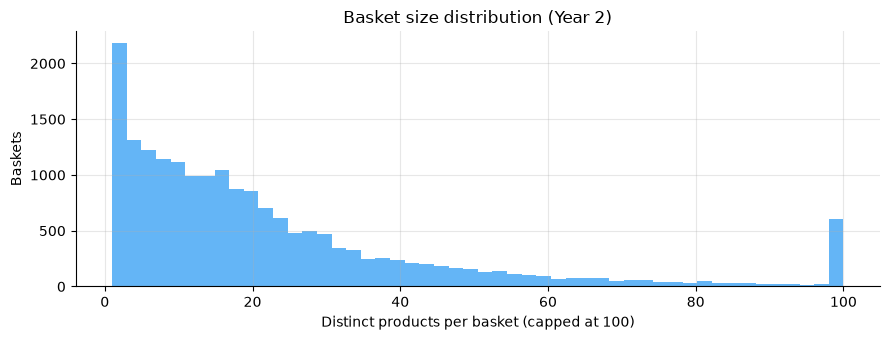

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(size.clip(upper=100), bins=50, color="#64B5F6")
ax.set_xlabel("Distinct products per basket (capped at 100)"); ax.set_ylabel("Baskets")
ax.set_title("Basket size distribution (Year 2)")
fig.tight_layout(); fig.savefig(FIG / "bq5_basket_size.png", dpi=150); plt.show()

## Frequent itemsets and rules

The basket × product table is one-hot encoded (True if the product is in the basket).
Products below the minimum support are dropped from the columns first; by the Apriori property they cannot
appear in any frequent itemset, so the result is unchanged and the table is much smaller. All baskets stay as rows,
so support is still measured against every basket.

Rules are kept with a **single product on the right-hand side**, the form `arules` produces, so the two languages compare like with like.

In [4]:
item_support = baskets["stock_code"].value_counts() / n_baskets
keep = item_support.index[item_support >= MIN_SUPPORT]
b = baskets.loc[baskets["stock_code"].isin(keep)]
onehot = pd.crosstab(b["invoice"], b["stock_code"]).astype(bool)
onehot = onehot.reindex(size.index, fill_value=False)        # baskets with no frequent product stay as rows
print(f"One-hot table: {onehot.shape[0]:,} baskets x {onehot.shape[1]:,} frequent products")

freq = fpgrowth(onehot, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
try:
    rules = association_rules(freq, metric="confidence", min_threshold=MIN_CONF, num_itemsets=n_baskets)
except TypeError:                                             # older mlxtend versions
    rules = association_rules(freq, metric="confidence", min_threshold=MIN_CONF)
rules = rules.loc[rules["consequents"].apply(len) == 1].copy()

key = lambda s: " + ".join(sorted(s))
rules["lhs_codes"] = rules["antecedents"].apply(key)
rules["rhs_code"] = rules["consequents"].apply(key)
rules["rule_key"] = rules["lhs_codes"] + " => " + rules["rhs_code"]
rules["lhs"] = rules["antecedents"].apply(lambda s: " + ".join(names[c] for c in sorted(s)))
rules["rhs"] = rules["consequents"].apply(lambda s: names[next(iter(s))])
rules["count"] = (rules["support"] * n_baskets).round().astype(int)
rules["n_lhs"] = rules["antecedents"].apply(len)
rules = rules.sort_values(["lift", "rule_key"], ascending=[False, True]).reset_index(drop=True)

print(f"Frequent itemsets: {len(freq):,} "
      f"({(freq['itemsets'].apply(len) == 1).sum()} single, {(freq['itemsets'].apply(len) == 2).sum()} pairs, "
      f"{(freq['itemsets'].apply(len) == 3).sum()} triples)")
print(f"Rules: {len(rules):,}   (1 product on the left: {(rules['n_lhs'] == 1).sum()}, "
      f"2 products: {(rules['n_lhs'] == 2).sum()})")
print(f"Lift: median {rules['lift'].median():.1f}, max {rules['lift'].max():.1f}   "
      f"Confidence: median {rules['confidence'].median():.2f}")

One-hot table: 18,837 baskets x 814 frequent products
Frequent itemsets: 1,933 (814 single, 863 pairs, 256 triples)
Rules: 1,488   (1 product on the left: 731, 2 products: 757)
Lift: median 9.3, max 78.9   Confidence: median 0.51


## Strongest rules

In [5]:
show = ["lhs", "rhs", "support", "confidence", "lift", "count"]
print("Top 15 rules by lift:")
print(rules[show].head(15).to_string())
print("\nTop 10 rules by support (most common combinations, confidence >= 30%):")
print(rules.sort_values(["support", "rule_key"], ascending=[False, True])[show].head(10).to_string())

Top 15 rules by lift:
                                           lhs                   rhs  support  confidence    lift  count
0      HERB MARKER THYME + HERB MARKER PARSLEY  HERB MARKER ROSEMARY   0.0103      0.9510 78.9146    194
1   HERB MARKER ROSEMARY + HERB MARKER PARSLEY     HERB MARKER THYME   0.0103      0.9510 78.9146    194
2        HERB MARKER THYME + HERB MARKER BASIL  HERB MARKER ROSEMARY   0.0100      0.9497 78.8124    189
3     HERB MARKER ROSEMARY + HERB MARKER BASIL     HERB MARKER THYME   0.0100      0.9356 77.6419    189
4     HERB MARKER THYME + HERB MARKER ROSEMARY   HERB MARKER PARSLEY   0.0103      0.9238 76.9991    194
5                            HERB MARKER THYME  HERB MARKER ROSEMARY   0.0111      0.9251 76.7678    210
6                         HERB MARKER ROSEMARY     HERB MARKER THYME   0.0111      0.9251 76.7678    210
7                            HERB MARKER THYME   HERB MARKER PARSLEY   0.0108      0.8987 74.9044    204
8                         HERB MA

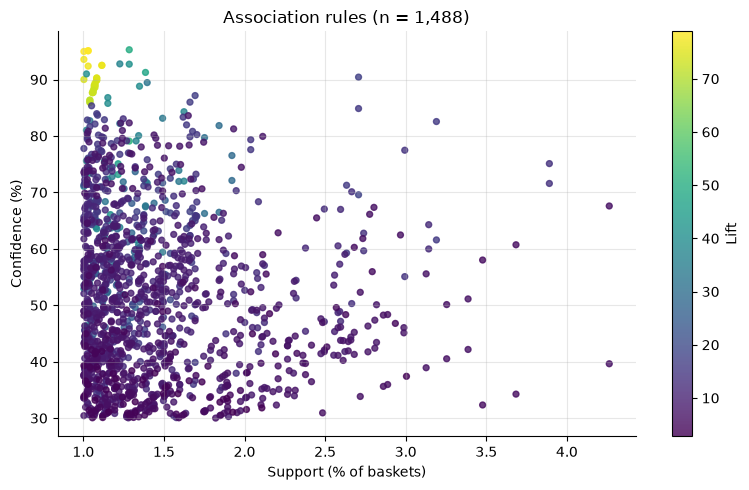

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rules["support"] * 100, rules["confidence"] * 100, c=rules["lift"], cmap="viridis",
                s=18, alpha=0.8)
fig.colorbar(sc, label="Lift")
ax.set_xlabel("Support (% of baskets)"); ax.set_ylabel("Confidence (%)")
ax.set_title(f"Association rules (n = {len(rules):,})")
fig.tight_layout(); fig.savefig(FIG / "bq5_rules_scatter.png", dpi=150); plt.show()

## Product pairs: one row per pair

`{A} → {B}` and `{B} → {A}` share the same support and lift, so for cross-selling it is easier to read one row per pair,
with both confidences side by side.

In [7]:
pairs = rules.loc[rules["n_lhs"] == 1].copy()
pairs["a"] = pairs[["lhs_codes", "rhs_code"]].min(axis=1)
pairs["b"] = pairs[["lhs_codes", "rhs_code"]].max(axis=1)
conf_ab = pairs.loc[pairs["lhs_codes"] == pairs["a"]].set_index(["a", "b"])["confidence"]
conf_ba = pairs.loc[pairs["lhs_codes"] == pairs["b"]].set_index(["a", "b"])["confidence"]
pair_tbl = (pairs.groupby(["a", "b"]).agg(support=("support", "first"), lift=("lift", "first"))
            .join(conf_ab.rename("conf_a_to_b")).join(conf_ba.rename("conf_b_to_a")).reset_index())
pair_tbl.insert(1, "product_a", names.reindex(pair_tbl["a"]).values)
pair_tbl.insert(3, "product_b", names.reindex(pair_tbl["b"]).values)
pair_tbl = pair_tbl.sort_values(["lift", "a", "b"], ascending=[False, True, True]).reset_index(drop=True)
print(f"Distinct product pairs with at least one rule: {len(pair_tbl):,}\n")
print(pair_tbl[["product_a", "product_b", "support", "conf_a_to_b", "conf_b_to_a", "lift"]].head(15).to_string())

Distinct product pairs with at least one rule: 491

                           product_a                            product_b  support  conf_a_to_b  conf_b_to_a    lift
0                  HERB MARKER THYME                 HERB MARKER ROSEMARY   0.0111       0.9251       0.9251 76.7678
1                  HERB MARKER THYME                  HERB MARKER PARSLEY   0.0108       0.8987       0.9027 74.9044
2               HERB MARKER ROSEMARY                  HERB MARKER PARSLEY   0.0108       0.8987       0.9027 74.9044
3                HERB MARKER PARSLEY                     HERB MARKER MINT   0.0107       0.8938       0.8860 73.8448
4               HERB MARKER ROSEMARY                    HERB MARKER BASIL   0.0107       0.8899       0.8899 73.8434
5                HERB MARKER PARSLEY                    HERB MARKER BASIL   0.0107       0.8894       0.8855 73.8029
6               HERB MARKER ROSEMARY                     HERB MARKER MINT   0.0106       0.8811       0.8772 72.7916
7           

## Export for the dashboard

In [8]:
out = rules[["rule_key", "lhs", "rhs", "n_lhs", "support", "confidence", "lift", "count"]].copy()
out[["support", "confidence", "lift"]] = out[["support", "confidence", "lift"]].round(6)
out.to_csv(DASH / "basket_rules.csv", index=False)
pair_tbl.round(6).to_csv(DASH / "basket_pairs.csv", index=False)
top_items.reset_index().rename(columns={"index": "stock_code"}).round(6).to_csv(DASH / "basket_top_products.csv", index=False)
for f in ["basket_rules.csv", "basket_pairs.csv", "basket_top_products.csv"]:
    print(f"{f:<26} {len(pd.read_csv(DASH / f)):>6,} rows")

basket_rules.csv            1,488 rows
basket_pairs.csv              491 rows
basket_top_products.csv        10 rows
